# Cat, Dog and Horse Image Classifier

A convolutional neural network built with Keras built-in layers and utilities.

Expected folder layout (next to this notebook):

```
dataset/
    training/    cat/  dog/  horse/
    validation/  cat/  dog/  horse/
    testing/     cat/  dog/  horse/
```

Change `BASE_DIR` below if your folders live somewhere else.

## 1. Imports and configuration

In [4]:
import os
import json
import io
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report
from PIL import Image, ImageOps

print("TensorFlow version:", tf.__version__)

BASE_DIR = "dataset"
TRAIN_DIR = os.path.join(BASE_DIR, "training")
VAL_DIR = os.path.join(BASE_DIR, "validation")
TEST_DIR = os.path.join(BASE_DIR, "testing")

IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 30
SEED = 42

tf.keras.utils.set_random_seed(SEED)

TensorFlow version: 2.21.0


In [10]:

BASE_DIR = r"C:\Users\DELL\Desktop\CNN\CNN_Images\cnn_image_quiz_3000"

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "validation")
TEST_DIR = os.path.join(BASE_DIR, "test")


## 2. Load the data

`image_dataset_from_directory` reads the class names from the sub-folder names (alphabetical order: cat, dog, horse).

In [11]:
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED,
)

val_ds = keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)

Found 2100 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Classes: ['cat', 'dog', 'horse']


## 3. Look at a few training images

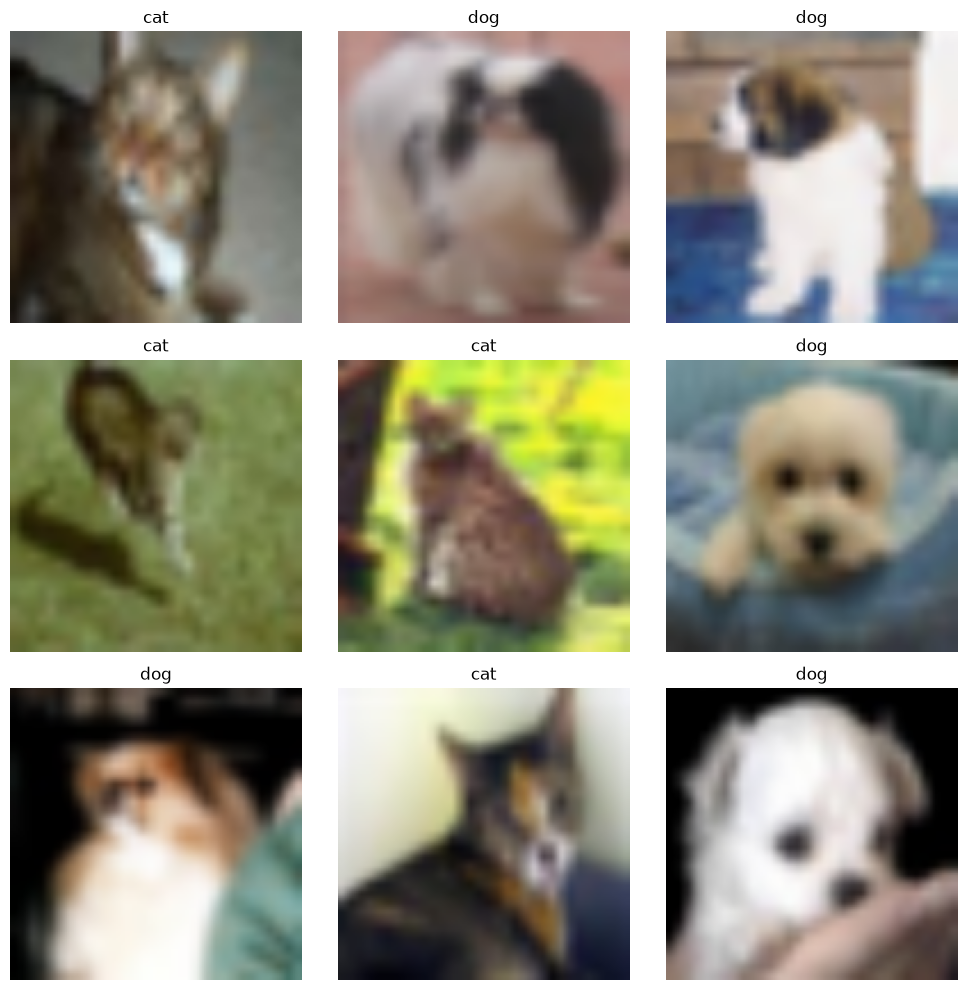

In [12]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Class balance check

In [13]:
def count_images(directory):
    return {c: len(os.listdir(os.path.join(directory, c))) for c in class_names}

for name, d in [("training", TRAIN_DIR), ("validation", VAL_DIR), ("testing", TEST_DIR)]:
    print(f"{name:>10}:", count_images(d))

  training: {'cat': 700, 'dog': 700, 'horse': 700}
validation: {'cat': 150, 'dog': 150, 'horse': 150}
   testing: {'cat': 150, 'dog': 150, 'horse': 150}


## 5. Speed up the input pipeline

In [14]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

## 6. Build the CNN

- Data augmentation layers (only active while training) reduce over-fitting.
- Rescaling is part of the model, so any image can be fed in as raw 0-255 pixels.
- Four convolution blocks (32, 64, 128, 256 filters) with batch normalization and max pooling.
- Global average pooling and dropout before the final softmax layer.

In [15]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.15),
        layers.RandomContrast(0.1),
    ],
    name="augmentation",
)


def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return x


inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 255)(x)

for f in (32, 64, 128, 256):
    x = conv_block(x, f)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

model = keras.Model(inputs, outputs, name="cat_dog_horse_cnn")
model.summary()

Model: "cat_dog_horse_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,208,419 (4.61 MB)

 Trainable params: 1,206,499 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 7. Compile and train

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.ModelCheckpoint("best_model.keras", monitor="val_accuracy",
                                    save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=3, min_lr=1e-6, verbose=1),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/30


d:\ancoda\mainfolder\envs\finvantage\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3781 - loss: 1.2306
Epoch 1: val_accuracy improved from None to 0.33778, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.3781 - loss: 1.2306 - val_accuracy: 0.3378 - val_loss: 1.2001 - learning_rate: 0.0010
Epoch 2/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4090 - loss: 1.1027
Epoch 2: val_accuracy improved from 0.33778 to 0.35333, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - accuracy: 0.4090 - loss: 1.1027 - val_accuracy: 0.3533 - val_loss: 1.1582 - learning_rate: 0.0010
Epoch 3/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.4471 - loss: 1.0344
Epoch 3: val_accuracy did not improve from 0.35333
66/66 ━━━━━━━━━━━━━━━━━━━━ 192s 3s/step - accuracy: 0.4471 - loss: 1.0344 - val_accuracy: 0.3333 - val_loss: 1.3861 - learning_rate: 0.0010
Epoch 4/30
6

## 8. Training curves

In [ ]:
acc, val_acc = history.history["accuracy"], history.history["val_accuracy"]
loss, val_loss = history.history["loss"], history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training", color="#3D1A5B")
plt.plot(epochs_range, val_acc, label="Validation", color="#B08FD0")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training", color="#3D1A5B")
plt.plot(epochs_range, val_loss, label="Validation", color="#B08FD0")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Evaluate on the unseen test set

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss:     {test_loss:.4f}")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print()
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

In [ ]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Purples")
ax.set_xticks(range(num_classes))
ax.set_yticks(range(num_classes))
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion matrix")

for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.colorbar(im)
plt.tight_layout()
plt.show()

## 10. Save the model

These two files are what the Streamlit app loads.

In [ ]:
model.save("cat_dog_horse_model.keras")

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Saved cat_dog_horse_model.keras and class_names.json")

## 11. Predict on your own image

Run the next cell, click **Upload**, and pick any image. The notebook shows the picture, the predicted category and the confidence for each class.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output


def preprocess(pil_img):
    pil_img = ImageOps.exif_transpose(pil_img).convert("RGB")
    resized = pil_img.resize((IMG_SIZE, IMG_SIZE))
    arr = np.asarray(resized, dtype="float32")
    return np.expand_dims(arr, axis=0)


def predict_image(pil_img):
    probs = model.predict(preprocess(pil_img), verbose=0)[0]
    idx = int(np.argmax(probs))
    return class_names[idx], float(probs[idx]), probs


def show_prediction(pil_img):
    label, conf, probs = predict_image(pil_img)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5),
                             gridspec_kw={"width_ratios": [1, 1]})
    axes[0].imshow(pil_img)
    axes[0].axis("off")
    axes[0].set_title("Uploaded image")

    colors = ["#3D1A5B" if n == label else "#C9B5DE" for n in class_names]
    axes[1].barh(class_names, probs * 100, color=colors)
    axes[1].set_xlim(0, 100)
    axes[1].set_xlabel("Confidence (%)")
    axes[1].set_title(f"Prediction: {label} ({conf * 100:.1f}%)")
    axes[1].invert_yaxis()

    plt.tight_layout()
    plt.show()


uploader = widgets.FileUpload(accept="image/*", multiple=False, description="Upload")
output = widgets.Output()


def on_upload(change):
    with output:
        clear_output(wait=True)
        value = uploader.value
        item = value[0] if isinstance(value, (tuple, list)) else list(value.values())[0]
        img = Image.open(io.BytesIO(bytes(item["content"])))
        show_prediction(img)


uploader.observe(on_upload, names="value")
display(uploader, output)

### Alternative: predict from a file path

In [ ]:
# Replace with the path to any image on your computer
# img = Image.open("my_photo.jpg")
# show_prediction(img)